<a href="https://colab.research.google.com/github/Rani-Wheeza/wals-linguistic-association-analysis/blob/main/notebooks/01_wals_data_understanding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Exploring Linguistic Associations Using WALS

## Project Overview

This project investigates relationships between grammatical word-order patterns and tonal features across the world's languages using the World Atlas of Language Structures (WALS).

The analysis uses the Apriori association-rule mining algorithm to identify frequent combinations of linguistic features and evaluate the strength of these associations.

The project follows the CRISP-DM methodology.

## Research Question

What associations exist between grammatical word-order patterns and tonal features across the world's languages, and how do these associations vary across language families and geographical regions?

## Research Objectives

1. Identify the most frequent combinations of word-order patterns and tonal features.
2. Determine which associations are stronger than expected under independence using support, confidence and lift.
3. Compare the identified patterns across language families and geographical regions.


*Still deciding if i will impliment this. It will depend on if i have time towards the end*

### Supplementary Comparative Investigation

A supplementary case study will compare Bantu languages represented in Uganda and South Africa.

The investigation will examine similarities and differences in grammatical word-order patterns and tonal features using the same four linguistic variables selected from WALS.

The comparison will explore whether these linguistic characteristics remain similar across different geographical regions and branches of the Bantu language family.

The inclusion of individual languages will depend on their availability and completeness within the WALS dataset.


## Dataset

**Source:** World Atlas of Language Structures (WALS)

**Version:** v2020.6

**Download:** https://zenodo.org/records/23010827

The dataset was downloaded manually from Zenodo and extracted. Four CSV files were selected and uploaded to Google Colab:

- `values.csv` – Linguistic observations
- `languages.csv` – Language metadata
- `parameters.csv` – Linguistic feature definitions
- `codes.csv` – Feature category descriptions

The original CSV files will remain unchanged. Any cleaning and transformation will be performed using Python.


### Loading the Data

The WALS v2020.6 dataset was downloaded from Zenodo and the four required CSV files
(`values.csv`, `languages.csv`, `parameters.csv`, `codes.csv`) are uploaded manually to the
Colab session before running the notebook. Copies of the original files are also stored,
unchanged, in the repository's `data/raw/` folder.

To run this notebook: open the Files panel in Colab, upload the four CSV files from
`data/raw/`, then run all cells in order.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:

# Import pandas for working with tabular data
import os
import pandas as pd

# Incase no files are available or uploaded
required_files = ["values.csv", "languages.csv", "parameters.csv", "codes.csv"]

missing = [f for f in required_files if not os.path.exists(f)]
if missing:
    raise FileNotFoundError(
        f"Please upload these WALS files to Colab before running: {missing}"
    )

# Load the four original WALS CSV files
values = pd.read_csv("/content/values.csv")
languages = pd.read_csv("/content/languages.csv")
parameters = pd.read_csv("/content/parameters.csv")
codes = pd.read_csv("/content/codes.csv")

print("All four WALS datasets loaded successfully.")

All four WALS datasets loaded successfully.



## 2. Data Understanding

### 2.1 Dataset Dimensions

This section examines the number of rows and columns in each WALS dataset.

Understanding the dataset dimensions provides an initial overview of the amount of available data before selecting features and performing data preparation.


In [6]:
# Display the dimensions of each dataset

print("WALS Dataset Dimensions:")
print("-" * 35)
print("Values:", values.shape)
print("Languages:", languages.shape)
print("Parameters:", parameters.shape)
print("Codes:", codes.shape)

WALS Dataset Dimensions:
-----------------------------------
Values: (76475, 8)
Languages: (3573, 17)
Parameters: (192, 5)
Codes: (1143, 6)



### 2.2 Dataset Column Inspection

This section examines the column names in each dataset to understand the information available and identify the variables relevant to the research.

The inspection will help establish how linguistic observations can be connected to language metadata and feature definitions.


In [7]:

# Display column names for each dataset

datasets = {
    "Values": values,
    "Languages": languages,
    "Parameters": parameters,
    "Codes": codes
}

for name, dataset in datasets.items():
    print(f"\n{name} Dataset Columns")
    print("-" * 40)

    for column in dataset.columns:
        print(column)



Values Dataset Columns
----------------------------------------
ID
Language_ID
Parameter_ID
Value
Code_ID
Comment
Source
Example_ID

Languages Dataset Columns
----------------------------------------
ID
Name
Macroarea
Latitude
Longitude
Glottocode
ISO639P3code
Family
Subfamily
Genus
GenusIcon
ISO_codes
Samples_100
Samples_200
Country_ID
Source
Parent_ID

Parameters Dataset Columns
----------------------------------------
ID
Name
Description
ColumnSpec
Chapter_ID

Codes Dataset Columns
----------------------------------------
ID
Parameter_ID
Name
Description
Number
icon



### 2.3 Initial Data Inspection

This section examines the first few records from each dataset.

The purpose is to understand how linguistic observations, language metadata, feature definitions and category descriptions are represented in the original WALS data.


In [8]:

# Display the first five records from each dataset

print("VALUES DATASET")
display(values.head())

print("LANGUAGES DATASET")
display(languages.head())

print("PARAMETERS DATASET")
display(parameters.head())

print("CODES DATASET")
display(codes.head())


VALUES DATASET


,ID,Language_ID,Parameter_ID,Value,Code_ID,Comment,Source,Example_ID
0,81A-aab,aab,81A,2,81A-2,NaN,Nekitel-1985[94],NaN
1,82A-aab,aab,82A,1,82A-1,NaN,Nekitel-1985[94],NaN
2,83A-aab,aab,83A,2,83A-2,NaN,Nekitel-1985[94],NaN
3,87A-aab,aab,87A,2,87A-2,NaN,Nekitel-1985[95],NaN
4,88A-aab,aab,88A,2,88A-2,NaN,Nekitel-1985[95],NaN


LANGUAGES DATASET


,ID,Name,Macroarea,Latitude,Longitude,Glottocode,ISO639P3code,Family,Subfamily,Genus,GenusIcon,ISO_codes,Samples_100,Samples_200,Country_ID,Source,Parent_ID
0,aab,Arapesh (Abu),Papunesia,-3.450000,142.950000,abua1245,aah,Torricelli,NaN,Kombio-Arapesh,NaN,aah,False,False,PG,Nekitel-1985,genus-kombioarapesh
1,aar,Aari,Africa,6.000000,36.583333,aari1239,aiw,Afro-Asiatic,Omotic,South Omotic,NaN,aiw,False,False,ET,Hayward-1990a,genus-southomotic
2,aba,Abau,Papunesia,-4.000000,141.250000,abau1245,aau,Sepik,NaN,Abau,NaN,aau,False,False,PG,Bailey-1975,genus-abau
3,abb,Arabic (Chadian),Africa,13.833333,20.833333,chad1249,shu,Afro-Asiatic,NaN,Semitic,NaN,shu,False,False,TD,Abu-Absi-1995,genus-semitic
4,abd,Abidji,Africa,5.666667,-4.583333,abid1235,abi,Niger-Congo,Kwa,Agneby,NaN,abi,False,False,CI,NaN,genus-agneby


PARAMETERS DATASET


,ID,Name,Description,ColumnSpec,Chapter_ID
0,1A,Consonant Inventories,NaN,NaN,1
1,2A,Vowel Quality Inventories,NaN,NaN,2
2,3A,Consonant-Vowel Ratio,NaN,NaN,3
3,4A,Voicing in Plosives and Fricatives,NaN,NaN,4
4,5A,Voicing and Gaps in Plosive Systems,NaN,NaN,5


CODES DATASET


,ID,Parameter_ID,Name,Description,Number,icon
0,1A-1,1A,Small,Small,1,c0000dd
1,1A-2,1A,Moderately small,Moderately small,2,c9999ff
2,1A-3,1A,Average,Average,3,cffffff
3,1A-4,1A,Moderately large,Moderately large,4,cff66ff
4,1A-5,1A,Large,Large,5,cdd0000



### 2.4 Understanding Feature Definitions and Categories

This section examines the selected linguistic feature definitions and their associated categories.

The purpose is to understand how WALS represents the different linguistic patterns and how numerical values correspond to meaningful category descriptions.


In [9]:

# Display our four selected linguistic features

selected_features = ["81A", "13A", "85A", "87A"]

print("SELECTED FEATURE DEFINITIONS")
display(
    parameters[
        parameters["ID"].isin(selected_features)
    ]
)

# Display the possible categories for these features

print("SELECTED FEATURE CATEGORIES")
display(
    codes[
        codes["Parameter_ID"].isin(selected_features)
    ].sort_values(["Parameter_ID", "Number"])
)


SELECTED FEATURE DEFINITIONS


,ID,Name,Description,ColumnSpec,Chapter_ID
13,13A,Tone,NaN,NaN,13
86,81A,"Order of Subject, Object and Verb",NaN,NaN,81
91,85A,Order of Adposition and Noun Phrase,NaN,NaN,85
93,87A,Order of Adjective and Noun,NaN,NaN,87


SELECTED FEATURE CATEGORIES


,ID,Parameter_ID,Name,Description,Number,icon
56,13A-1,13A,No tones,No tones,1,cffffff
57,13A-2,13A,Simple tone system,Simple tone system,2,cff66ff
58,13A-3,13A,Complex tone system,Complex tone system,3,cdd0000
404,81A-1,81A,SOV,Subject-object-verb (SOV),1,c0000dd
405,81A-2,81A,SVO,Subject-verb-object (SVO),2,cdd0000
406,81A-3,81A,VSO,Verb-subject-object (VSO),3,cffff00
407,81A-4,81A,VOS,Verb-object-subject (VOS),4,dffff00
408,81A-5,81A,OVS,Object-verb-subject (OVS),5,ddd0000
409,81A-6,81A,OSV,Object-subject-verb (OSV),6,d0000dd
410,81A-7,81A,No dominant order,Lacking a dominant word order,7,ccccccc


The four selected WALS features represent different grammatical and tonal characteristics of languages. Before analysing the data, it is important to understand the categories available for each feature.

The following code displays the category codes, names and descriptions associated with each selected feature. This helps identify what each category represents and how WALS classifies the different linguistic characteristics. Understanding these categories will be important when preparing the data for association rule mining.

In [10]:
# Display the available categories for each selected WALS feature

for feature in selected_features:

    # Retrieve the name of the current feature
    feature_name = parameters.loc[
        parameters["ID"] == feature, "Name"
    ].iloc[0]

    print("\n" + "=" * 60)
    print(f"FEATURE: {feature} - {feature_name}")
    print("=" * 60)

    # Retrieve and display the categories associated with the feature
    feature_codes = codes[
        codes["Parameter_ID"] == feature
    ][["ID", "Name", "Description", "Number"]]

    display(feature_codes.sort_values("Number"))


FEATURE: 81A - Order of Subject, Object and Verb


,ID,Name,Description,Number
404,81A-1,SOV,Subject-object-verb (SOV),1
405,81A-2,SVO,Subject-verb-object (SVO),2
406,81A-3,VSO,Verb-subject-object (VSO),3
407,81A-4,VOS,Verb-object-subject (VOS),4
408,81A-5,OVS,Object-verb-subject (OVS),5
409,81A-6,OSV,Object-subject-verb (OSV),6
410,81A-7,No dominant order,Lacking a dominant word order,7



FEATURE: 13A - Tone


,ID,Name,Description,Number
56,13A-1,No tones,No tones,1
57,13A-2,Simple tone system,Simple tone system,2
58,13A-3,Complex tone system,Complex tone system,3



FEATURE: 85A - Order of Adposition and Noun Phrase


,ID,Name,Description,Number
428,85A-1,Postpositions,Postpositions,1
429,85A-2,Prepositions,Prepositions,2
430,85A-3,Inpositions,Inpositions,3
431,85A-4,No dominant order,More than one adposition type with none dominant,4
432,85A-5,No adpositions,No adpositions,5



FEATURE: 87A - Order of Adjective and Noun


,ID,Name,Description,Number
436,87A-1,Adjective-Noun,Modifying adjective precedes noun (AdjN),1
437,87A-2,Noun-Adjective,Modifying adjective follows noun (NAdj),2
438,87A-3,No dominant order,Both orders of noun and modifying adjective oc...,3
439,87A-4,Only internally-headed relative clauses,"Adjectives do not modify nouns, occurring as p...",4


### Interpretation of Selected Feature Categories

The inspection of the WALS feature definitions and category codes identified the possible grammatical and tonal classifications available for the four selected features.

- **81A – Order of Subject, Object and Verb:** Identifies the dominant arrangement of subjects, objects and verbs within a sentence.
- **13A – Tone:** Classifies languages according to whether they have no tones, a simple tone system or a complex tone system.
- **85A – Order of Adposition and Noun Phrase:** Identifies the position of adpositions in relation to noun phrases.
- **87A – Order of Adjective and Noun:** Identifies whether adjectives generally precede or follow the nouns they modify.

These features provide categorical data that can be examined for associations across languages. Understanding their available categories is necessary before preparing the dataset for association rule mining.

The next stage will involve examining data quality, missing values and the availability of observations for each selected feature.

### 2.5 Initial Data Quality Assessment

Before preparing the data for analysis, an initial data quality assessment is required to identify missing values in the datasets.

This step examines the completeness of the four WALS tables to determine whether important information is missing. Identifying missing values early will help guide decisions about data cleaning and ensure that incomplete observations are handled appropriately.

###Missing-value assessment
The following code checks each WALS dataset for missing values. It calculates the number and percentage of missing entries in every column. This will help identify incomplete information that may need to be addressed during data preparation.


In [11]:
# Check the number and percentage of missing values in each dataset

for name, dataset in datasets.items():

    print(f"\n{name} Dataset - Missing Values")
    print("-" * 50)

    missing_summary = pd.DataFrame({
        "Missing Values": dataset.isnull().sum(),
        "Missing Percentage (%)": (
            dataset.isnull().mean() * 100
        ).round(2)
    })

    display(missing_summary)


Values Dataset - Missing Values
--------------------------------------------------


,Missing Values,Missing Percentage (%)
ID,0,0.00
Language_ID,74,0.10
Parameter_ID,0,0.00
Value,0,0.00
Code_ID,0,0.00
Comment,74102,96.90
Source,7092,9.27
Example_ID,74863,97.89



Languages Dataset - Missing Values
--------------------------------------------------


,Missing Values,Missing Percentage (%)
ID,1,0.03
Name,0,0.00
Macroarea,911,25.50
Latitude,911,25.50
Longitude,911,25.50
Glottocode,928,25.97
ISO639P3code,960,26.87
Family,911,25.50
Subfamily,2662,74.50
Genus,911,25.50



Parameters Dataset - Missing Values
--------------------------------------------------


,Missing Values,Missing Percentage (%)
ID,0,0.0
Name,0,0.0
Description,192,100.0
ColumnSpec,192,100.0
Chapter_ID,0,0.0



Codes Dataset - Missing Values
--------------------------------------------------


,Missing Values,Missing Percentage (%)
ID,0,0.00
Parameter_ID,0,0.00
Name,16,1.40
Description,4,0.35
Number,0,0.00
icon,0,0.00


### Initial Missing-Value Findings

The missing-value assessment identified incomplete information across the four WALS datasets.

The Values dataset contains 74 observations with missing Language_ID values. The Languages dataset also contains missing information in several geographical and linguistic classification fields.

Further investigation is required to distinguish individual language records from classification entries and determine whether missing identifiers affect the four selected features.

Some supplementary fields, such as comments, examples and descriptions, also contain missing values. These fields are not essential to the planned association rule analysis.

### Identifying Individual Language Records

The WALS Languages dataset contains both individual language records and linguistic classification entries. Classification entries represent language families, subfamilies and genera rather than individual languages.

These entries can be identified by prefixes in their IDs, such as `family-`, `subfamily-` and `genus-`.

The following code identifies and counts these classification entries to establish how many individual language records are available for analysis.

In [12]:
# Identify and count linguistic classification records

classification_prefixes = (
    "family-",
    "subfamily-",
    "genus-"
)

is_classification = languages["ID"].str.startswith(
    classification_prefixes,
    na=False
)

print("Total records:", len(languages))
print("Classification records:", is_classification.sum())
print("Individual language records:", (~is_classification).sum())

Total records: 3573
Classification records: 911
Individual language records: 2662


The Languages dataset contains 3,573 records, of which 911 are linguistic classification entries and 2,662 are individual language records.

The classification entries are not individual languages and will not form part of the language-level analysis. The individual language records will be used as the basis for further data preparation.

### Assessing Individual Language Metadata

After distinguishing classification entries from individual languages, the remaining records are examined for missing information in fields relevant to the project.

Particular attention is given to language identifiers, geographical macroareas, language families, subfamilies and country associations. These fields will support the identification and comparison of languages across linguistic families and geographical regions.

In [13]:
# Create a dataset containing individual language records

individual_languages = languages.loc[
    ~is_classification
].copy()

print("Individual language records:", len(individual_languages))

# Check missing values in relevant metadata fields

relevant_columns = [
    "ID",
    "Macroarea",
    "Family",
    "Subfamily",
    "Country_ID"
]

display(
    pd.DataFrame({
        "Missing Values": individual_languages[relevant_columns].isnull().sum(),
        "Missing Percentage (%)": (
            individual_languages[relevant_columns].isnull().mean() * 100
        ).round(2)
    })
)

Individual language records: 2662


,Missing Values,Missing Percentage (%)
ID,1,0.04
Macroarea,0,0.00
Family,0,0.00
Subfamily,1751,65.78
Country_ID,10,0.38


The 2,662 individual language records contain complete Macroarea and Family information, supporting the planned geographical and language-family comparisons.

However, some records have missing subfamily classifications, and ten records lack Country_ID information. One record, Nandi, also has a missing language identifier. These limitations will be considered during data preparation, depending on the requirements of each analysis.

### Missing Language Identifiers in Selected Features

The Values dataset contains 74 observations with missing Language_ID values. Since Language_ID is required to connect feature observations with individual language records, these observations may affect the analysis.

The following check focuses on the four selected features to identify how many observations have missing language identifiers.

In [14]:
# Identify missing Language_ID values affecting selected features

missing_value_languages = values[
    values["Language_ID"].isnull()
]

selected_missing = missing_value_languages[
    missing_value_languages["Parameter_ID"].isin(selected_features)
]

print("Total observations with missing Language_ID:",
      len(missing_value_languages))

print("Missing Language_ID observations in selected features:",
      len(selected_missing))

display(
    selected_missing[
        ["ID", "Language_ID", "Parameter_ID", "Value", "Code_ID"]
    ]
)

Total observations with missing Language_ID: 74
Missing Language_ID observations in selected features: 4


,ID,Language_ID,Parameter_ID,Value,Code_ID
47648,13A-nan,NaN,13A,2,13A-2
47675,81A-nan,NaN,81A,3,81A-3
47679,85A-nan,NaN,85A,2,85A-2
47681,87A-nan,NaN,87A,2,87A-2


The investigation identified four observations with missing Language_ID values among the selected features, with one affected observation per feature.

Although these observations contain recorded feature categories, they cannot be reliably associated with individual languages. Their treatment will therefore be addressed during Data Preparation.

### Duplicate Observation Assessment

Before combining the selected linguistic features, it is necessary to check for duplicate observations.

Each individual language should ideally have only one recorded category for each selected feature. Multiple observations for the same language-feature combination could create inconsistencies when preparing the data for association rule mining.

The following code identifies repeated combinations of Language_ID and Parameter_ID among observations with a recorded language identifier.

In [15]:
# Check for duplicate language-feature combinations

selected_values = values[
    (values["Parameter_ID"].isin(selected_features)) &
    (values["Language_ID"].notna())
].copy()

duplicate_observations = selected_values[
    selected_values.duplicated(
        subset=["Language_ID", "Parameter_ID"],
        keep=False
    )
].sort_values(["Language_ID", "Parameter_ID"])

print("Number of duplicate observations:",
      len(duplicate_observations))

display(duplicate_observations)

Number of duplicate observations: 0


,ID,Language_ID,Parameter_ID,Value,Code_ID,Comment,Source,Example_ID


The duplicate assessment found no repeated language-feature combinations among observations with recorded Language_ID values. This indicates that each observed language-feature combination has a single recorded entry in the selected data, allowing the dataset to proceed to further preparation.

### Selected Feature Data Coverage

The final check examines the availability of observations for each of the four selected linguistic features.

It calculates the number of individual languages with recorded data for each feature and identifies how many languages have complete observations across all four features.

This is important because association rule mining requires observations containing the selected feature combinations. The results will help determine the amount of data available for the analysis before data preparation begins.

In [16]:
# Calculate the number of language observations available for each feature

feature_coverage = (
    selected_values.groupby("Parameter_ID")["Language_ID"]
    .nunique()
    .reindex(selected_features, fill_value=0)
    .reset_index()
)

feature_coverage.columns = [
    "Feature",
    "Languages with Recorded Observations"
]

print("Language Coverage by Selected Feature:")
display(feature_coverage)


# Identify languages with observations for all four selected features

feature_matrix = selected_values.pivot(
    index="Language_ID",
    columns="Parameter_ID",
    values="Value"
)

complete_languages = feature_matrix.dropna(
    subset=selected_features
)

print("Languages with at least one selected feature:",
      len(feature_matrix))

print("Languages with complete observations across all four features:",
      len(complete_languages))

print("Languages missing at least one selected feature:",
      len(feature_matrix) - len(complete_languages))

Language Coverage by Selected Feature:


,Feature,Languages with Recorded Observations
0,81A,1375
1,13A,526
2,85A,1183
3,87A,1366


Languages with at least one selected feature: 1719
Languages with complete observations across all four features: 304
Languages missing at least one selected feature: 1415


### Interpretation of Feature Coverage

The coverage assessment shows that the four selected WALS features have different levels of data availability. Feature 81A has the highest number of recorded observations (1,375), while Feature 13A (Tone) has the lowest (526).

Out of 1,719 languages with at least one selected feature recorded, 304 have complete observations across all four features. The remaining 1,415 languages are missing at least one of the selected features.

This difference in coverage is important for the analysis. Using only languages with complete observations across all four features would reduce the available sample to 304 languages. This may affect how representative the results are of the world's languages.

During Data Preparation, the approach to missing feature observations will be considered carefully to balance data completeness and the amount of information retained.

### 3.1 Selecting the Relevant Linguistic Features

The original WALS Values dataset contains observations for 192 linguistic features. However, this research focuses on four selected features: 81A, 13A, 85A and 87A.

The first preparation step filters the Values dataset to retain only observations belonging to these four features.

Observations with missing Language_ID values are excluded because they cannot be reliably connected to individual language records in the Languages dataset. The original dataset remains unchanged, and all preparation is performed on a separate working copy.

In [17]:
# Select observations belonging to the four research features

prepared_values = values[
    values["Parameter_ID"].isin(selected_features)
].copy()

print("Selected feature observations:",
      len(prepared_values))


# Identify and exclude observations with missing Language_ID

missing_ids = prepared_values["Language_ID"].isnull().sum()

prepared_values = prepared_values[
    prepared_values["Language_ID"].notna()
].copy()

print("Observations excluded due to missing Language_ID:",
      missing_ids)

print("Remaining observations:",
      len(prepared_values))

print("\nObservations per selected feature:")
display(
    prepared_values["Parameter_ID"].value_counts().sort_index()
)

Selected feature observations: 4454
Observations excluded due to missing Language_ID: 4
Remaining observations: 4450

Observations per selected feature:


,count
Parameter_ID,
13A,526
81A,1375
85A,1183
87A,1366


### Interpretation of Feature Selection

The filtering process identified 4,454 observations belonging to the four selected linguistic features.

Four observations had missing Language_ID values and were excluded because they could not be linked to individual language records. This left 4,450 observations for further preparation.

The remaining observations retain the same feature counts identified during Data Understanding, confirming that the filtering process has preserved the available data for the selected features.

The original WALS Values dataset remains unchanged.

### 3.2 Joining Language Metadata

The selected linguistic observations need to be connected to the Languages dataset to provide additional information about each language.

The datasets will be joined using the language identifier:
- `Language_ID` in the Values dataset.
- `ID` in the Languages dataset.

Relevant metadata, including language name, macroarea, family, subfamily, genus and country, will be included.

A left join will be used to preserve all selected linguistic observations while checking whether each observation has a matching language record.

In [18]:
# Select the language metadata required for the analysis

language_metadata = individual_languages.loc[
    individual_languages["ID"].notna(),
    [
        "ID",
        "Name",
        "Macroarea",
        "Family",
        "Subfamily",
        "Genus",
        "Country_ID"
    ]
].copy()

# Rename ID so it matches Language_ID in the Values dataset

language_metadata = language_metadata.rename(
    columns={"ID": "Language_ID"}
)


# Join linguistic observations with language metadata

prepared_data = prepared_values.merge(
    language_metadata,
    on="Language_ID",
    how="left",
    validate="many_to_one",
    indicator=True
)


# Check the join results

matched = (prepared_data["_merge"] == "both").sum()
unmatched = (prepared_data["_merge"] == "left_only").sum()

print("Total observations:", len(prepared_data))
print("Successfully matched observations:", matched)
print("Observations without matching language metadata:", unmatched)

print("\nJoin status:")
display(prepared_data["_merge"].value_counts())

print("\nPreview of the joined dataset:")
display(prepared_data.head())

Total observations: 4450
Successfully matched observations: 4450
Observations without matching language metadata: 0

Join status:


,count
_merge,
both,4450
left_only,0
right_only,0



Preview of the joined dataset:


,ID,Language_ID,Parameter_ID,Value,Code_ID,Comment,Source,Example_ID,Name,Macroarea,Family,Subfamily,Genus,Country_ID,_merge
0,81A-aab,aab,81A,2,81A-2,NaN,Nekitel-1985[94],NaN,Arapesh (Abu),Papunesia,Torricelli,NaN,Kombio-Arapesh,PG,both
1,87A-aab,aab,87A,2,87A-2,NaN,Nekitel-1985[95],NaN,Arapesh (Abu),Papunesia,Torricelli,NaN,Kombio-Arapesh,PG,both
2,85A-aar,aar,85A,1,85A-1,NaN,Hayward-1990a[489-490],NaN,Aari,Africa,Afro-Asiatic,Omotic,South Omotic,ET,both
3,87A-aar,aar,87A,2,87A-2,NaN,Hayward-1990a[460-461],NaN,Aari,Africa,Afro-Asiatic,Omotic,South Omotic,ET,both
4,81A-aba,aba,81A,1,81A-1,NaN,Bailey-1975[passim],NaN,Abau,Papunesia,Sepik,NaN,Abau,PG,both


### Interpretation of the Metadata Join

The left join successfully matched all 4,450 selected linguistic observations with their corresponding language metadata records.

No unmatched observations were identified. This confirms that the selected observations can be connected to the Languages dataset using Language_ID.

The joined dataset now contains the linguistic observations alongside relevant information about each language, including its name, geographical macroarea, language family, genus and country.

The successful join provides a foundation for the geographical and language-family comparisons planned in this research.

### 3.3 Mapping Feature Categories

The selected linguistic observations contain numerical values and category identifiers rather than fully descriptive category names.

The WALS Codes dataset provides the descriptions associated with these categories.

The Code_ID column in the prepared dataset will be matched with the ID column in codes.csv. This will allow each observation to be associated with its corresponding category name and description.

A left join will preserve all observations while allowing unmatched category identifiers to be identified and investigated.

In [20]:
# Select the relevant category information from the Codes dataset

feature_codes = codes[
    [
        "ID",
        "Parameter_ID",
        "Name",
        "Description"
    ]
].copy()

# Rename columns for clarity

feature_codes = feature_codes.rename(
    columns={
        "ID": "Code_ID",
        "Name": "Category_Name",
        "Description": "Category_Description"
    }
)


# Remove columns from any previous category-mapping attempt

prepared_data = prepared_data.drop(
    columns=[
        "category_match",
        "Category_Name",
        "Category_Description"
    ],
    errors="ignore"
)


# Join category information to the prepared dataset

prepared_data = prepared_data.merge(
    feature_codes,
    on="Code_ID",
    how="left",
    validate="many_to_one",
    indicator="category_match"
)


# Check the category mapping results

matched_categories = (
    prepared_data["category_match"] == "both"
).sum()

unmatched_categories = (
    prepared_data["category_match"] == "left_only"
).sum()

print("Total observations:", len(prepared_data))
print("Successfully mapped categories:", matched_categories)
print("Unmatched categories:", unmatched_categories)

print("\nPreview of mapped categories:")

display(
    prepared_data[
        [
            "Language_ID",
            "Name",
            "Parameter_ID",
            "Value",
            "Code_ID",
            "Category_Name",
            "Category_Description"
        ]
    ].head(10)
)

Total observations: 4450
Successfully mapped categories: 4450
Unmatched categories: 0

Preview of mapped categories:


,Language_ID,Name,Parameter_ID,Value,Code_ID,Category_Name,Category_Description
0,aab,Arapesh (Abu),81A,2,81A-2,SVO,Subject-verb-object (SVO)
1,aab,Arapesh (Abu),87A,2,87A-2,Noun-Adjective,Modifying adjective follows noun (NAdj)
2,aar,Aari,85A,1,85A-1,Postpositions,Postpositions
3,aar,Aari,87A,2,87A-2,Noun-Adjective,Modifying adjective follows noun (NAdj)
4,aba,Abau,81A,1,81A-1,SOV,Subject-object-verb (SOV)
5,aba,Abau,85A,1,85A-1,Postpositions,Postpositions
6,abi,Abipón,81A,2,81A-2,SVO,Subject-verb-object (SVO)
7,abi,Abipón,85A,2,85A-2,Prepositions,Prepositions
8,abi,Abipón,87A,3,87A-3,No dominant order,Both orders of noun and modifying adjective oc...
9,abk,Abkhaz,13A,1,13A-1,No tones,No tones


### Interpretation of Feature Category Mapping

The category mapping successfully matched all 4,450 linguistic observations with their corresponding entries in the WALS Codes dataset.

No unmatched category identifiers were found.

The numerical feature categories have now been supplemented with readable category names and descriptions. For example, numerical codes for word order have been translated into categories such as SOV and SVO.

This makes the dataset easier to interpret and provides meaningful categorical values for the subsequent association rule mining process.

### 3.4 Reshaping the Dataset

The prepared dataset currently uses a long format, where each row represents an observation for one linguistic feature belonging to a particular language.

Association rule mining requires the selected features to be represented together for each language.

The dataset will therefore be transformed into a wide format using a pivot operation:

- Each row will represent an individual language.
- Each column will represent one of the four selected WALS features.
- Each cell will contain the corresponding linguistic category.

Missing observations will remain as missing values rather than being assigned an artificial category. Their treatment will be considered in a later preparation step.

In [21]:
# Reshape the dataset from long format to wide format

feature_matrix = prepared_data.pivot(
    index="Language_ID",
    columns="Parameter_ID",
    values="Category_Name"
)

# Keep the selected features in the intended order

feature_matrix = feature_matrix.reindex(
    columns=selected_features
)

# Check the reshaped dataset

print("Reshaped dataset dimensions:", feature_matrix.shape)

print("\nNumber of available observations per feature:")
display(feature_matrix.notna().sum())

print("\nPreview of the reshaped dataset:")
display(feature_matrix.head(10))

Reshaped dataset dimensions: (1719, 4)

Number of available observations per feature:


,0
Parameter_ID,
81A,1375
13A,526
85A,1183
87A,1366



Preview of the reshaped dataset:


Parameter_ID,81A,13A,85A,87A
Language_ID,,,,
aab,SVO,NaN,NaN,Noun-Adjective
aar,NaN,NaN,Postpositions,Noun-Adjective
aba,SOV,NaN,Postpositions,NaN
abi,SVO,NaN,Prepositions,No dominant order
abk,SOV,No tones,Postpositions,Noun-Adjective
abn,SOV,NaN,NaN,Noun-Adjective
abo,SOV,NaN,NaN,Noun-Adjective
abu,SVO,NaN,Prepositions,Noun-Adjective
abv,SOV,NaN,No adpositions,Noun-Adjective


### Interpretation of Dataset Reshaping

The pivot operation successfully transformed the prepared dataset from long format into wide format.

The resulting feature matrix contains 1,719 individual language records and four columns representing the selected WALS features: 81A, 13A, 85A and 87A.

The number of available observations for each feature remains consistent with the earlier Data Understanding assessment.

Missing values have been preserved as NaN rather than being assigned artificial categories. Only 304 languages currently have complete observations across all four features.

The reshaped dataset provides the required structure for examining combinations of linguistic characteristics.

### 3.5 Assessing Missing Feature Observations

The reshaped dataset contains missing observations across the four selected linguistic features.

Removing every language with at least one missing feature would reduce the dataset to 304 complete language records.

However, the main research question focuses on associations between grammatical word order and tonal features. Therefore, languages with observations for these two features may still be useful even when other selected features are missing.

This section compares the available language counts for different feature combinations to support an evidence-based decision about the dataset used for association rule mining.

In [22]:
# Compare language coverage for different feature combinations

feature_combinations = {
    "Word Order and Tone": ["81A", "13A"],
    "Word Order and Adposition Order": ["81A", "85A"],
    "Word Order and Adjective Order": ["81A", "87A"],
    "Tone and Adposition Order": ["13A", "85A"],
    "Tone and Adjective Order": ["13A", "87A"],
    "All Four Features": ["81A", "13A", "85A", "87A"]
}

coverage_results = []

for combination, features in feature_combinations.items():

    available_languages = feature_matrix[features].dropna()

    coverage_results.append({
        "Feature Combination": combination,
        "Number of Languages": len(available_languages)
    })

coverage_summary = pd.DataFrame(coverage_results)

display(coverage_summary)

,Feature Combination,Number of Languages
0,Word Order and Tone,372
1,Word Order and Adposition Order,1027
2,Word Order and Adjective Order,1181
3,Tone and Adposition Order,345
4,Tone and Adjective Order,367
5,All Four Features,304


### Interpretation of Feature Combination Coverage

The coverage assessment shows that the number of available languages varies depending on the selected feature combination.

The primary comparison between word order (81A) and tone (13A) has 372 languages with observations for both features. This provides a larger sample than restricting the analysis to the 304 languages with complete observations across all four features.

Comparisons involving tone have lower coverage because Feature 13A has fewer recorded observations than the other selected features.

These findings support using separate datasets for different stages of the analysis:

- The primary word-order and tone investigation will use languages with observations for both features.
- The broader four-feature investigation will use languages with complete observations across all four features.

This approach retains more data for the main research question while ensuring that missing observations are not incorrectly treated as linguistic categories.

### 3.6 Preparing the Analysis Datasets

Based on the feature coverage assessment, two datasets will be prepared for the analysis.

**Primary analysis dataset:** Contains languages with recorded observations for both Feature 81A (Order of Subject, Object and Verb) and Feature 13A (Tone).

**Broader analysis dataset:** Contains languages with complete observations across all four selected features.

The relevant language metadata will also be retained to support comparisons across language families and geographical regions.

Both datasets will be created separately, leaving the original prepared feature matrix unchanged.

In [23]:
# Create the primary dataset using word order and tone

primary_analysis = (
    feature_matrix
    .dropna(subset=["81A", "13A"])
    .copy()
    .reset_index()
)


# Create the broader dataset using all four features

broader_analysis = (
    feature_matrix
    .dropna(subset=selected_features)
    .copy()
    .reset_index()
)


# Select one metadata record per language

language_info = prepared_data[
    [
        "Language_ID",
        "Name",
        "Macroarea",
        "Family",
        "Subfamily",
        "Genus",
        "Country_ID"
    ]
].drop_duplicates(subset="Language_ID")


# Add language metadata to both analysis datasets

primary_analysis = primary_analysis.merge(
    language_info,
    on="Language_ID",
    how="left",
    validate="one_to_one"
)

broader_analysis = broader_analysis.merge(
    language_info,
    on="Language_ID",
    how="left",
    validate="one_to_one"
)


# Display dataset dimensions

print("Primary analysis dataset:", primary_analysis.shape)
print("Broader analysis dataset:", broader_analysis.shape)

print("\nPrimary analysis preview:")
display(primary_analysis.head())

print("\nBroader analysis preview:")
display(broader_analysis.head())

Primary analysis dataset: (372, 11)
Broader analysis dataset: (304, 11)

Primary analysis preview:


,Language_ID,81A,13A,85A,87A,Name,Macroarea,Family,Subfamily,Genus,Country_ID
0,abk,SOV,No tones,Postpositions,Noun-Adjective,Abkhaz,Eurasia,Northwest Caucasian,NaN,Northwest Caucasian,GE
1,acm,SVO,Simple tone system,Prepositions,NaN,Achumawi,North America,Hokan,Palaihnihan,Achumawi,US
2,aco,No dominant order,Complex tone system,Postpositions,No dominant order,Acoma,North America,Keresan,NaN,Keresan,US
3,aeg,SVO,No tones,Prepositions,Noun-Adjective,Arabic (Egyptian),Africa,Afro-Asiatic,NaN,Semitic,EG
4,agh,SVO,Simple tone system,NaN,Noun-Adjective,Aghem,Africa,Niger-Congo,Benue-Congo,Wide Grassfields,CM



Broader analysis preview:


,Language_ID,81A,13A,85A,87A,Name,Macroarea,Family,Subfamily,Genus,Country_ID
0,abk,SOV,No tones,Postpositions,Noun-Adjective,Abkhaz,Eurasia,Northwest Caucasian,NaN,Northwest Caucasian,GE
1,aco,No dominant order,Complex tone system,Postpositions,No dominant order,Acoma,North America,Keresan,NaN,Keresan,US
2,aeg,SVO,No tones,Prepositions,Noun-Adjective,Arabic (Egyptian),Africa,Afro-Asiatic,NaN,Semitic,EG
3,ain,SOV,Simple tone system,Postpositions,Adjective-Noun,Ainu,Eurasia,Ainu,NaN,Ainu,JP
4,akn,SVO,Simple tone system,No dominant order,Noun-Adjective,Akan,Africa,Niger-Congo,Kwa,Tano,GH


### Interpretation of Analysis Dataset Preparation

Two separate analysis datasets were successfully created based on the feature coverage assessment.

The primary analysis dataset contains 372 languages with recorded observations for both word order (81A) and tone (13A).

The broader analysis dataset contains 304 languages with complete observations across all four selected features.

Both datasets contain 11 columns, including the selected linguistic features and relevant language metadata.

The language metadata has been retained to support comparisons across language families and geographical regions.

These datasets provide the basis for the subsequent exploratory analysis and association rule mining.

### 3.7 Validating the Analysis Datasets

Before proceeding to exploratory data analysis, the two prepared datasets must be checked for consistency and completeness.

The validation will examine:

- Duplicate language records.
- Missing language identifiers.
- Missing language names.
- Missing language family and geographical information.

These checks will help identify any remaining data quality issues that could affect the analysis.

In [24]:
# Validate the primary and broader analysis datasets

analysis_datasets = {
    "Primary Analysis": primary_analysis,
    "Broader Analysis": broader_analysis
}

for dataset_name, dataset in analysis_datasets.items():

    print(f"\n{dataset_name} Dataset Validation")
    print("-" * 45)

    print("Total language records:", len(dataset))

    print(
        "Duplicate language identifiers:",
        dataset["Language_ID"].duplicated().sum()
    )

    print(
        "Missing language identifiers:",
        dataset["Language_ID"].isnull().sum()
    )

    # Check missing values in important metadata fields
    metadata_columns = [
        "Name",
        "Macroarea",
        "Family",
        "Country_ID"
    ]

    print("\nMissing metadata values:")

    display(dataset[metadata_columns].isnull().sum())


Primary Analysis Dataset Validation
---------------------------------------------
Total language records: 372
Duplicate language identifiers: 0
Missing language identifiers: 0

Missing metadata values:


,0
Name,0
Macroarea,0
Family,0
Country_ID,1



Broader Analysis Dataset Validation
---------------------------------------------
Total language records: 304
Duplicate language identifiers: 0
Missing language identifiers: 0

Missing metadata values:


,0
Name,0
Macroarea,0
Family,0
Country_ID,1


### Interpretation of Dataset Validation

Both analysis datasets passed the validation checks.

Neither dataset contains duplicate language identifiers or missing language identifiers. All language records also have complete language names, macroarea information and language family classifications.

One language in each dataset has a missing Country_ID. This does not affect the primary word-order and tone analysis or comparisons by language family and geographical macroarea. However, this limitation will be considered if country-level comparisons are performed.

The two datasets are therefore considered suitable for the next stage of analysis.

### 4.1 Distribution of Word Order and Tone Categories

The first exploratory analysis examines the frequency and distribution of categories within the two features used in the primary investigation.

Feature 81A represents the dominant order of Subject, Object and Verb, while Feature 13A classifies languages according to their tonal systems.

The category frequencies and percentages will be calculated using the primary analysis dataset, which contains 372 languages with observations for both features.

This provides an overview of the linguistic characteristics represented in the primary analysis sample.

In [25]:
# Examine the distribution of word order and tone categories

primary_features = ["81A", "13A"]

for feature in primary_features:

    print(f"\nFeature {feature} - Category Distribution")
    print("-" * 50)

    category_counts = primary_analysis[feature].value_counts()

    category_summary = pd.DataFrame({
        "Frequency": category_counts,
        "Percentage (%)": (
            category_counts / len(primary_analysis) * 100
        ).round(2)
    })

    display(category_summary)


Feature 81A - Category Distribution
--------------------------------------------------


,Frequency,Percentage (%)
81A,,
SOV,151,40.59
SVO,121,32.53
No dominant order,65,17.47
VSO,21,5.65
VOS,9,2.42
OVS,5,1.34



Feature 13A - Category Distribution
--------------------------------------------------


,Frequency,Percentage (%)
13A,,
No tones,226,60.75
Simple tone system,85,22.85
Complex tone system,61,16.40


### Interpretation of Word Order and Tone Distributions

The distribution of Feature 81A shows that Subject-Object-Verb (SOV) is the most frequent word-order pattern, representing 40.59% of the 372 languages. Subject-Verb-Object (SVO) follows at 32.53%. Together, these two patterns account for 73.12% of the sample. The remaining languages are distributed across other word-order categories, with OVS being the least frequent.

For Feature 13A, 60.75% of the languages have no tones, while 22.85% have a simple tone system and 16.40% have a complex tone system.

These distributions provide an initial overview of the linguistic characteristics represented in the primary dataset. However, frequency distributions alone do not establish whether particular word-order patterns are associated with tonal features. This relationship will be investigated through association rule mining.

### 4.2 Visualising Word Order and Tone Distributions

Bar charts are used to visualise the frequency of each category within Features 81A and 13A. This makes it easier to identify the most and least common linguistic patterns.

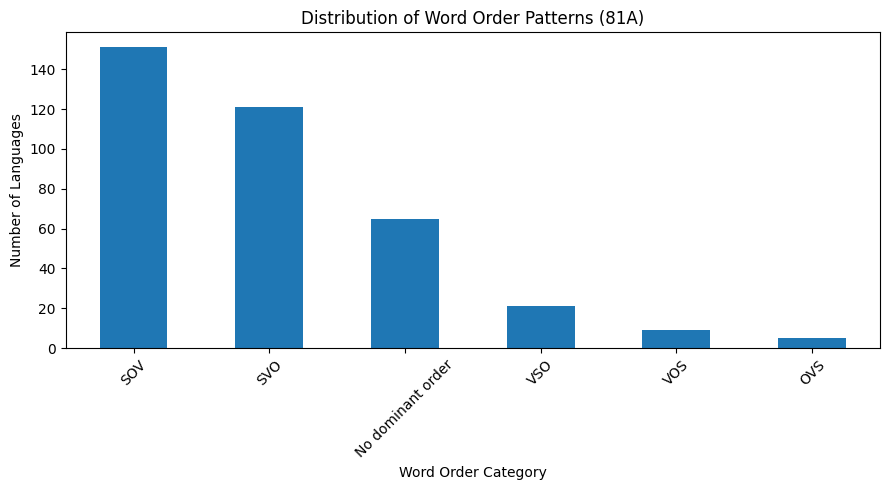

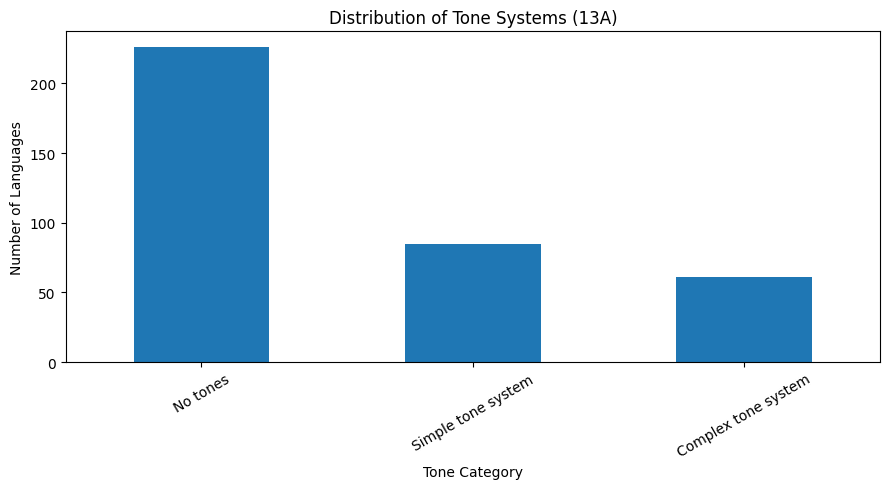

In [26]:
import matplotlib.pyplot as plt

# Plot word order distribution
plt.figure(figsize=(9, 5))

primary_analysis["81A"].value_counts().plot(
    kind="bar",
    rot=45
)

plt.title("Distribution of Word Order Patterns (81A)")
plt.xlabel("Word Order Category")
plt.ylabel("Number of Languages")
plt.tight_layout()
plt.show()


# Plot tone distribution
plt.figure(figsize=(9, 5))

primary_analysis["13A"].value_counts().plot(
    kind="bar",
    rot=30
)

plt.title("Distribution of Tone Systems (13A)")
plt.xlabel("Tone Category")
plt.ylabel("Number of Languages")
plt.tight_layout()
plt.show()

### Interpretation of Word Order and Tone Visualisations

The bar charts provide a visual representation of the category distributions identified in the previous frequency analysis.

For Feature 81A, SOV and SVO are the most prominent word-order patterns, while the remaining categories occur less frequently. OVS is the least represented pattern in the primary dataset.

For Feature 13A, languages without tones form the largest category, followed by languages with simple and complex tone systems.

The visualisations highlight differences in category representation within the dataset. However, they do not establish whether specific word-order patterns are associated with particular tonal systems.

The next analysis will examine the relationship between these two features using a cross-tabulation and a statistical test of association.

### 4.3 Exploring the Relationship Between Word Order and Tone

This section examines the relationship between Feature 81A (Order of Subject, Object and Verb) and Feature 13A (Tone).

A cross-tabulation will be used to compare the frequency of each word-order category across the three tonal categories.

This will help identify which combinations occur most frequently and whether certain word-order patterns appear more commonly alongside particular tonal systems.

The analysis uses the 372 languages in the primary analysis dataset.

In [27]:
# Create a cross-tabulation of word order and tone

word_order_tone_table = pd.crosstab(
    primary_analysis["81A"],
    primary_analysis["13A"]
)

print("Word Order and Tone Cross-Tabulation:")
display(word_order_tone_table)


# Calculate row percentages

word_order_tone_percentages = (
    pd.crosstab(
        primary_analysis["81A"],
        primary_analysis["13A"],
        normalize="index"
    ) * 100
).round(2)

print("\nWord Order and Tone - Row Percentages:")
display(word_order_tone_percentages)

Word Order and Tone Cross-Tabulation:


13A,Complex tone system,No tones,Simple tone system
81A,,,
No dominant order,6,51,8
OVS,0,4,1
SOV,14,101,36
SVO,36,51,34
VOS,1,7,1
VSO,4,12,5



Word Order and Tone - Row Percentages:


13A,Complex tone system,No tones,Simple tone system
81A,,,
No dominant order,9.23,78.46,12.31
OVS,0.00,80.00,20.00
SOV,9.27,66.89,23.84
SVO,29.75,42.15,28.10
VOS,11.11,77.78,11.11
VSO,19.05,57.14,23.81


### Interpretation of Word Order and Tone Cross-Tabulation

The cross-tabulation reveals differences in the distribution of tonal systems across word-order categories.

The most frequent combination is SOV with no tones, representing 101 languages. SOV languages also show a higher proportion of observations without tones (66.89%) compared with SVO languages (42.15%).

SVO languages show a more balanced distribution across the three tonal categories. They also have the highest proportion of complex tone systems among the main word-order categories, at 29.75%.

Less frequent word-order categories, including VOS and OVS, have considerably fewer observations. Their distributions should therefore be interpreted cautiously.

These findings suggest potential relationships between word-order patterns and tonal systems. However, cross-tabulation alone cannot establish whether the observed differences represent statistically significant associations.

A statistical test will be required to investigate this further.

### 4.4 Statistical Test of Association

A Chi-square test of independence will be used to investigate whether word-order patterns (81A) and tonal categories (13A) are statistically associated.

The test compares the observed frequencies in the cross-tabulation with the frequencies that would be expected if the two linguistic features were independent.

The following measures will be examined:

- Chi-square statistic: Measures the difference between observed and expected frequencies.
- P-value: Indicates whether the observed association is statistically significant.
- Degrees of freedom: Represents the degrees of freedom used in the test.
- Expected frequencies: Used to assess whether the assumptions of the Chi-square test are satisfied.

Cramér's V will also be calculated to measure the strength of the association.

The analysis uses the 372 languages in the primary dataset.

In [28]:
from scipy.stats import chi2_contingency
import numpy as np

# Perform the Chi-square test of independence

chi2, p_value, degrees_of_freedom, expected = chi2_contingency(
    word_order_tone_table
)

# Calculate Cramér's V

sample_size = word_order_tone_table.to_numpy().sum()

minimum_dimension = min(word_order_tone_table.shape) - 1

cramers_v = np.sqrt(
    chi2 / (sample_size * minimum_dimension)
)

# Display statistical results

print("Chi-square Test of Independence")
print("-" * 45)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Degrees of freedom: {degrees_of_freedom}")
print(f"Cramer's V: {cramers_v:.4f}")

# Assess expected frequency assumptions

expected_values = expected.flatten()

print("\nExpected Frequency Assessment")
print("-" * 45)

print("Minimum expected frequency:",
      round(expected_values.min(), 2))

print("Cells with expected frequency below 5:",
      (expected_values < 5).sum())

print("Percentage of cells below 5:",
      round((expected_values < 5).mean() * 100, 2), "%")

Chi-square Test of Independence
---------------------------------------------
Chi-square statistic: 38.1533
P-value: 0.000036
Degrees of freedom: 10
Cramer's V: 0.2265

Expected Frequency Assessment
---------------------------------------------
Minimum expected frequency: 0.82
Cells with expected frequency below 5: 7
Percentage of cells below 5: 38.89 %


### Interpretation of Initial Chi-square Test

The initial Chi-square test produced a statistic of 38.1533 and a p-value of 0.000036. Cramér's V was calculated as 0.227, suggesting a relatively modest association between word-order patterns and tonal categories.

However, the expected frequency assessment identified seven cells (38.89%) with expected frequencies below five, including a minimum expected frequency of 0.82.

This exceeds the commonly used guideline for the Chi-square approximation. Therefore, the initial p-value should not be interpreted as definitive evidence of a statistically significant association.

A permutation-based test will be performed as an alternative approach to assess the relationship while accounting for the observed category frequencies.

### 4.5 Permutation Test of Independence

A permutation test will be used to further investigate the relationship between word order and tone.

The test randomly rearranges the tonal category labels across languages while preserving the original word-order and tonal category frequencies.

This creates a reference distribution under the assumption that word order and tone are independent.

The observed Chi-square statistic will then be compared with the statistics obtained from the random permutations.

A fixed random seed will be used to make the results reproducible.

In [29]:
# Perform a permutation test of independence

import numpy as np

observed_table = word_order_tone_table.to_numpy()

# Calculate the observed Chi-square statistic
observed_chi2 = chi2

# Extract word-order and tone labels
word_order_labels = primary_analysis["81A"].to_numpy()
tone_labels = primary_analysis["13A"].to_numpy()

# Set up the permutation test
number_of_permutations = 10000
random_generator = np.random.default_rng(42)

permuted_statistics = []

# Randomly shuffle tone labels while keeping word order unchanged
for _ in range(number_of_permutations):

    shuffled_tones = random_generator.permutation(tone_labels)

    shuffled_table = pd.crosstab(
        word_order_labels,
        shuffled_tones
    ).reindex(
        index=word_order_tone_table.index,
        columns=word_order_tone_table.columns,
        fill_value=0
    ).to_numpy()

    expected_table = expected

    permutation_chi2 = np.sum(
        (shuffled_table - expected_table) ** 2 / expected_table
    )

    permuted_statistics.append(permutation_chi2)

# Calculate the permutation p-value
permuted_statistics = np.array(permuted_statistics)

extreme_results = np.sum(
    permuted_statistics >= observed_chi2
)

permutation_p_value = (
    extreme_results + 1
) / (
    number_of_permutations + 1
)

print("Permutation Test Results")
print("-" * 45)

print("Observed Chi-square statistic:",
      round(observed_chi2, 4))

print("Number of permutations:",
      number_of_permutations)

print("Permutations with equal or greater statistic:",
      extreme_results)

print("Permutation p-value:",
      round(permutation_p_value, 6))

Permutation Test Results
---------------------------------------------
Observed Chi-square statistic: 38.1533
Number of permutations: 10000
Permutations with equal or greater statistic: 2
Permutation p-value: 0.0003


### Interpretation of Permutation Test

The permutation test was performed using 10,000 random permutations to investigate the association between word-order patterns and tonal categories.

The observed Chi-square statistic was 38.1533. Only two permutations produced a statistic equal to or greater than the observed value, resulting in a permutation p-value of 0.0003.

Since this value is below the significance threshold of 0.05, the results provide evidence of an association between word-order patterns and tonal systems in the primary analysis sample.

Combined with the Cramér's V value of 0.227, the findings suggest a statistically significant but relatively modest association.

These results do not establish causation. They indicate that the distribution of tonal categories differs across word-order patterns within the 372 languages analysed.

### 4.6 Visualising the Relationship Between Word Order and Tone

A heatmap will be used to visualise the relationship between word-order patterns (81A) and tonal categories (13A).

The heatmap displays the number of languages within each combination. Darker and lighter areas will help highlight combinations with higher and lower frequencies.

This visualisation complements the cross-tabulation and statistical test by providing a clearer overview of the observed distributions.


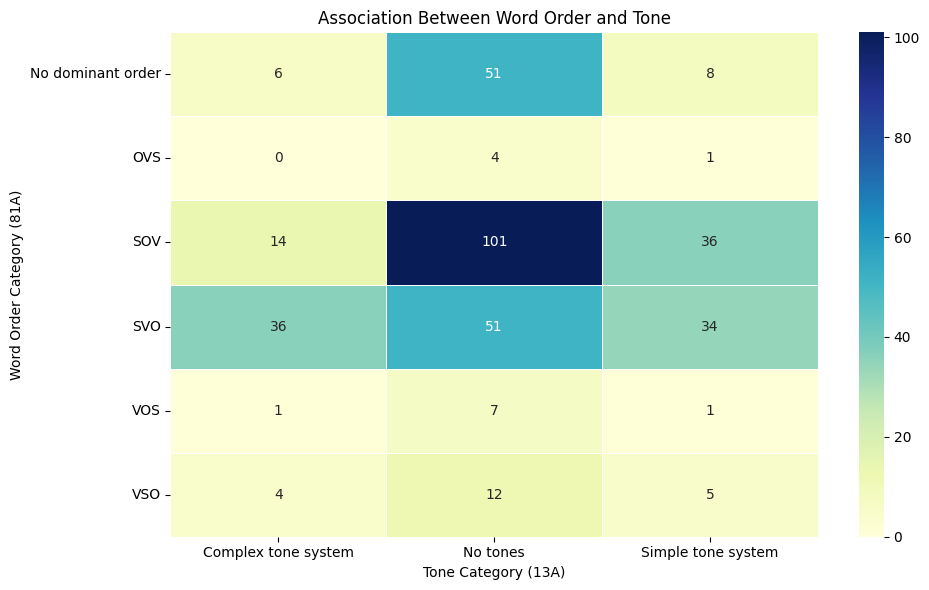

In [30]:
# Visualise word order and tone combinations using a heatmap

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.heatmap(
    word_order_tone_table,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Association Between Word Order and Tone")
plt.xlabel("Tone Category (13A)")
plt.ylabel("Word Order Category (81A)")
plt.tight_layout()
plt.show()

### Interpretation of Word Order and Tone Heatmap

The heatmap provides a visual comparison of the frequency of word-order and tonal combinations across the 372 languages.

The most frequent combination is SOV with no tones, occurring in 101 languages. Other notable combinations include SVO with complex tone systems (36 languages) and SOV with simple tone systems (36 languages).

The less frequent word-order categories, particularly OVS and VOS, contain substantially fewer observations across the tonal categories.

These visual patterns complement the cross-tabulation and permutation test results. They provide further insight into the distribution of linguistic characteristics but do not establish causal relationships.

### 5.1 Preparing Data for Apriori Association Rule Mining

The primary analysis dataset contains categorical observations for word order (81A) and tone (13A).

The Apriori algorithm requires transaction-style data in which each linguistic category is represented as a binary item.

One-hot encoding will therefore be applied to the two selected features. Each language will be represented by a row containing binary indicators for its recorded word-order and tonal categories.

This transformation allows the algorithm to identify combinations of linguistic characteristics that occur together across languages.

The primary analysis dataset of 372 languages will be used for this investigation.

In [31]:
# Select the two features for the primary Apriori analysis

apriori_input = primary_analysis[["81A", "13A"]].copy()

# Convert categorical features into binary columns

transaction_data = pd.get_dummies(
    apriori_input,
    prefix=["Word_Order", "Tone"],
    dtype=int
)

# Check the transaction dataset

print("Transaction dataset dimensions:", transaction_data.shape)

print("\nPreview of the transaction dataset:")
display(transaction_data.head(10))

print("\nCheck binary values:")
print(transaction_data.stack().unique())

print("\nNumber of items per language:")
print(transaction_data.sum(axis=1).value_counts())

Transaction dataset dimensions: (372, 9)

Preview of the transaction dataset:


,Word_Order_No dominant order,Word_Order_OVS,Word_Order_SOV,Word_Order_SVO,Word_Order_VOS,Word_Order_VSO,Tone_Complex tone system,Tone_No tones,Tone_Simple tone system
0,0,0,1,0,0,0,0,1,0
1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,0,0,1,0,0
3,0,0,0,1,0,0,0,1,0
4,0,0,0,1,0,0,0,0,1
5,0,0,1,0,0,0,0,0,1
6,0,0,0,1,0,0,0,0,1
7,0,0,1,0,0,0,0,1,0
8,0,0,0,1,0,0,0,1,0
9,1,0,0,0,0,0,0,1,0



Check binary values:
[0 1]

Number of items per language:
2    372
Name: count, dtype: int64


### 5.2 Identifying Frequent Itemsets Using Apriori

The Apriori algorithm will be applied to the one-hot encoded transaction dataset to identify frequently occurring combinations of word-order and tonal categories.

The minimum support threshold is set to 0.05 (5%). This means that a combination must occur in at least 5% of the 372 languages to be considered frequent.

Only itemsets containing a maximum of two categories will be examined, as each language has one word-order category and one tonal category.

The resulting frequent itemsets will provide the foundation for generating association rules.

In [32]:
# Import the Apriori algorithm

from mlxtend.frequent_patterns import apriori

# Set the minimum support threshold
minimum_support = 0.05

# Identify frequent itemsets
frequent_itemsets = apriori(
    transaction_data,
    min_support=minimum_support,
    use_colnames=True,
    max_len=2
)

# Display the results
print("Minimum support:", minimum_support)

print("Number of frequent itemsets:",
      len(frequent_itemsets))

print("\nFrequent Itemsets:")
display(
    frequent_itemsets.sort_values(
        by="support",
        ascending=False
    ).reset_index(drop=True)
)

Minimum support: 0.05
Number of frequent itemsets: 13

Frequent Itemsets:


/usr/local/lib/python3.13/dist-packages/mlxtend/frequent_patterns/fpcommon.py:161: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
0,0.607527,(Tone_No tones)
1,0.405914,(Word_Order_SOV)
2,0.325269,(Word_Order_SVO)
3,0.271505,"(Word_Order_SOV, Tone_No tones)"
4,0.228495,(Tone_Simple tone system)
5,0.174731,(Word_Order_No dominant order)
6,0.163978,(Tone_Complex tone system)
7,0.137097,"(Tone_No tones, Word_Order_SVO)"
8,0.137097,"(Tone_No tones, Word_Order_No dominant order)"
9,0.096774,"(Tone_Complex tone system, Word_Order_SVO)"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Interpretation of Frequent Itemsets

The Apriori algorithm identified 13 frequent itemsets using a minimum support threshold of 5%.

Among the individual categories, languages without tones had the highest support (60.75%), followed by SOV word order (40.59%) and SVO word order (32.53%).

The most frequent combination was SOV with no tones, occurring in 101 languages and representing 27.15% of the primary dataset.

Other frequent combinations included SVO with no tones (13.71%), no dominant word order with no tones (13.71%), and SVO with complex tone systems (9.68%).

VOS and OVS did not appear among the frequent itemsets because their individual support values were below the selected threshold.

These findings identify commonly occurring linguistic combinations. However, support alone does not indicate whether the combinations represent stronger associations than would be expected by chance. Confidence and lift will be examined next.

### 5.3 Generating Association Rules

Association rules will be generated from the frequent itemsets identified by the Apriori algorithm.

The rules will examine relationships between word-order categories and tonal categories.

Three measures will be used:

- Support measures the frequency of the complete combination.
- Confidence measures the likelihood of the consequent occurring when the antecedent is present.
- Lift compares the observed association with the frequency expected under independence.

A minimum confidence threshold of 50% will initially be used to identify potentially useful rules. This is an exploratory filtering threshold rather than a statistical significance test.

In [33]:
# Generate association rules from the frequent itemsets

from mlxtend.frequent_patterns import association_rules

rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.50
)

# Keep rules connecting word order and tone

linguistic_rules = rules[
    rules["antecedents"].apply(
        lambda x: any(item.startswith("Word_Order_") for item in x)
    ) &
    rules["consequents"].apply(
        lambda x: any(item.startswith("Tone_") for item in x)
    )
].copy()

# Display the association rules

print("Number of word-order to tone rules:",
      len(linguistic_rules))

display(
    linguistic_rules[
        [
            "antecedents",
            "consequents",
            "support",
            "confidence",
            "lift"
        ]
    ].sort_values(
        by="lift",
        ascending=False
    ).reset_index(drop=True)
)

Number of word-order to tone rules: 2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,support,confidence,lift
0,(Word_Order_No dominant order),(Tone_No tones),0.137097,0.784615,1.291491
1,(Word_Order_SOV),(Tone_No tones),0.271505,0.668874,1.100979


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Interpretation of Word Order and Tone Association Rules

The Apriori algorithm identified two word-order-to-tone association rules using a minimum support threshold of 5% and a minimum confidence threshold of 50%.

The first rule, No Dominant Word Order → No Tones, has a support of 13.71%, confidence of 78.46% and lift of 1.2915. This indicates that 78.46% of languages without a dominant word order have no tones. Its lift suggests that this combination occurs approximately 29.15% more frequently than expected under independence.

The second rule, SOV → No Tones, has a support of 27.15%, confidence of 66.89% and lift of 1.1010. This indicates that 66.89% of languages with SOV word order have no tones. Its lift suggests a more modest positive association.

Both rules have lift values greater than one, indicating positive associations between the selected word-order and tonal categories.

The first rule has higher confidence and lift, while the second has higher support. This demonstrates the difference between the strength and frequency of an association.

These findings are exploratory and do not establish causal relationships. The selected support and confidence thresholds also influence which rules are identified.

### 5.4 Comparing Association Rule Strength

The two identified association rules will be compared using their support, confidence and lift values.

Bar charts will be used to visualise the differences between the rules:

- Support compares how frequently each combination occurs.
- Confidence compares how reliably the consequent occurs when the antecedent is present.
- Lift compares the observed association with the frequency expected under independence.

This comparison will help identify which linguistic relationship is more frequent and which demonstrates a stronger association.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

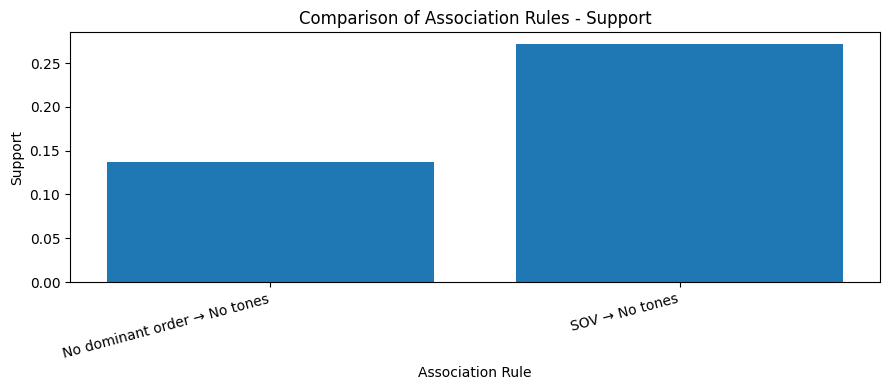

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

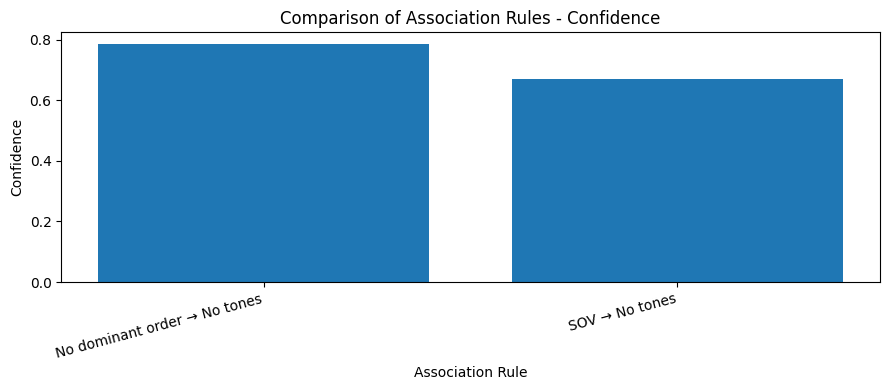

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

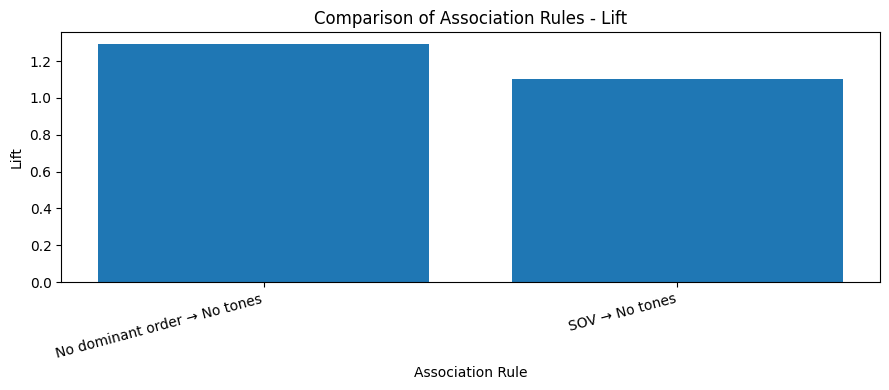

Association Rule Comparison:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Rule,support,confidence,lift
0,No dominant order → No tones,0.1371,0.7846,1.2915
1,SOV → No tones,0.2715,0.6689,1.1010


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [34]:
# Prepare readable labels for the association rules

rule_comparison = linguistic_rules.copy()

rule_comparison["Rule"] = rule_comparison.apply(
    lambda row:
        " + ".join(row["antecedents"]).replace("Word_Order_", "") +
        " → " +
        " + ".join(row["consequents"]).replace("Tone_", ""),
    axis=1
)

# Compare support, confidence and lift

metrics = [
    ("support", "Support"),
    ("confidence", "Confidence"),
    ("lift", "Lift")
]

for metric, title in metrics:

    plt.figure(figsize=(9, 4))

    plt.bar(
        rule_comparison["Rule"],
        rule_comparison[metric]
    )

    plt.title(f"Comparison of Association Rules - {title}")
    plt.xlabel("Association Rule")
    plt.ylabel(title)
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.show()


# Display the comparison table

print("Association Rule Comparison:")
display(
    rule_comparison[
        ["Rule", "support", "confidence", "lift"]
    ].round(4)
)

### Interpretation of Association Rule Comparison

The comparison of the two association rules reveals differences in their support, confidence and lift values.

The SOV → No Tones rule has the highest support (27.15%), indicating that it occurs more frequently across the primary dataset.

However, the No Dominant Word Order → No Tones rule has higher confidence (78.46%) and lift (1.2915). This suggests a stronger positive association between these characteristics relative to their individual frequencies.

The comparison demonstrates that the most frequent linguistic combination is not necessarily the strongest association.

Both rules have lift values greater than one, indicating positive associations. However, these findings should be interpreted as exploratory patterns rather than evidence of causal relationships.

### 5.5 Broader Four-Feature Association Analysis

The primary Apriori analysis focused on associations between word order (81A) and tone (13A).

To investigate additional grammatical relationships, a broader analysis will be performed using all four selected WALS features:

- 81A – Order of Subject, Object and Verb.
- 13A – Tone.
- 85A – Order of Adposition and Noun Phrase.
- 87A – Order of Adjective and Noun.

The broader dataset contains 304 languages with complete observations across all four features.

One-hot encoding will be applied to the four categorical features to prepare the dataset for Apriori association rule mining.

This analysis will help identify frequently occurring combinations involving multiple grammatical characteristics.

In [35]:
# Select all four linguistic features

broader_input = broader_analysis[
    ["81A", "13A", "85A", "87A"]
].copy()


# Convert the categorical features into binary indicators

broader_transactions = pd.get_dummies(
    broader_input,
    prefix=[
        "Word_Order",
        "Tone",
        "Adposition_Order",
        "Adjective_Order"
    ],
    dtype=int
)


# Validate the encoded dataset

print("Broader transaction dataset dimensions:",
      broader_transactions.shape)

print("\nPreview of encoded data:")
display(broader_transactions.head(10))

print("\nBinary values:")
print(broader_transactions.stack().unique())

print("\nNumber of active items per language:")
print(broader_transactions.sum(axis=1).value_counts())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Broader transaction dataset dimensions: (304, 18)

Preview of encoded data:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Word_Order_No dominant order,Word_Order_OVS,Word_Order_SOV,Word_Order_SVO,Word_Order_VOS,Word_Order_VSO,Tone_Complex tone system,Tone_No tones,Tone_Simple tone system,Adposition_Order_Inpositions,Adposition_Order_No adpositions,Adposition_Order_No dominant order,Adposition_Order_Postpositions,Adposition_Order_Prepositions,Adjective_Order_Adjective-Noun,Adjective_Order_No dominant order,Adjective_Order_Noun-Adjective,Adjective_Order_Only internally-headed relative clauses
0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0
1,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0
2,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,1,0
3,0,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0
4,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,1,0
5,0,0,1,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0
6,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,1,0
7,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0
8,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0
9,0,0,1,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0



Binary values:
[0 1]

Number of active items per language:
4    304
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### 5.6 Identifying Frequent Itemsets Across Four Features

The Apriori algorithm will be applied to the broader transaction dataset containing 304 languages and four linguistic features.

A minimum support threshold of 5% will be used. This requires a combination to occur in at least approximately 16 languages to be considered frequent.

The maximum itemset length will be set to four, allowing the investigation of combinations involving two, three or all four linguistic features.

The resulting frequent itemsets will be examined to identify recurring grammatical and tonal patterns across the broader dataset.

In [36]:
# Apply Apriori to the broader transaction dataset

broader_frequent_itemsets = apriori(
    broader_transactions,
    min_support=0.05,
    use_colnames=True,
    max_len=4
)

# Display the results

print("Minimum support: 0.05")

print("Number of frequent itemsets:",
      len(broader_frequent_itemsets))

print("\nFrequent Itemsets Across Four Features:")

display(
    broader_frequent_itemsets.sort_values(
        by=["support"],
        ascending=False
    ).reset_index(drop=True)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Minimum support: 0.05
Number of frequent itemsets: 69

Frequent Itemsets Across Four Features:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
0,0.625000,(Tone_No tones)
1,0.595395,(Adjective_Order_Noun-Adjective)
2,0.493421,(Adposition_Order_Postpositions)
3,0.407895,(Word_Order_SOV)
4,0.398026,(Adposition_Order_Prepositions)
...,...,...
64,0.055921,"(Tone_Simple tone system, Word_Order_SOV, Adje..."
65,0.055921,"(Adposition_Order_Prepositions, Adjective_Orde..."
66,0.055921,"(Adposition_Order_Prepositions, Word_Order_SVO..."
67,0.052632,"(Adposition_Order_Prepositions, Word_Order_VSO)"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [37]:
# Separate frequent itemsets by number of categories

broader_results = broader_frequent_itemsets.copy()

broader_results["Itemset Size"] = (
    broader_results["itemsets"].apply(len)
)

broader_results["Categories"] = (
    broader_results["itemsets"].apply(
        lambda items: " + ".join(sorted(items))
    )
)

broader_results["Number of Languages"] = (
    (broader_results["support"] * len(broader_transactions))
    .round()
    .astype(int)
)

# Display the 10 most frequent itemsets for each size

for size in [2, 3, 4]:

    print(f"\nTop 10 Frequent Itemsets - {size} Categories")
    print("-" * 65)

    display(
        broader_results[
            broader_results["Itemset Size"] == size
        ][
            ["Categories", "support", "Number of Languages"]
        ]
        .sort_values("support", ascending=False)
        .head(10)
        .reset_index(drop=True)
    )

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Top 10 Frequent Itemsets - 2 Categories
-----------------------------------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Categories,support,Number of Languages
0,Adposition_Order_Postpositions + Word_Order_SOV,0.375000,114
1,Adjective_Order_Noun-Adjective + Tone_No tones,0.328947,100
2,Adposition_Order_Postpositions + Tone_No tones,0.325658,99
3,Adjective_Order_Noun-Adjective + Adposition_Or...,0.296053,90
4,Tone_No tones + Word_Order_SOV,0.273026,83
5,Adjective_Order_Noun-Adjective + Word_Order_SVO,0.256579,78
6,Adposition_Order_Prepositions + Word_Order_SVO,0.256579,78
7,Adjective_Order_Adjective-Noun + Tone_No tones,0.253289,77
8,Adposition_Order_Prepositions + Tone_No tones,0.233553,71
9,Adjective_Order_Noun-Adjective + Adposition_Or...,0.230263,70



Top 10 Frequent Itemsets - 3 Categories
-----------------------------------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Categories,support,Number of Languages
0,Adposition_Order_Postpositions + Tone_No tones...,0.246711,75
1,Adjective_Order_Noun-Adjective + Adposition_Or...,0.197368,60
2,Adjective_Order_Adjective-Noun + Adposition_Or...,0.177632,54
3,Adjective_Order_Noun-Adjective + Adposition_Or...,0.171053,52
4,Adjective_Order_Adjective-Noun + Adposition_Or...,0.171053,52
5,Adjective_Order_Noun-Adjective + Adposition_Or...,0.164474,50
6,Adjective_Order_Adjective-Noun + Tone_No tones...,0.141447,43
7,Adjective_Order_Noun-Adjective + Adposition_Or...,0.128289,39
8,Adposition_Order_Prepositions + Tone_No tones ...,0.121711,37
9,Adjective_Order_Noun-Adjective + Tone_No tones...,0.115132,35



Top 10 Frequent Itemsets - 4 Categories
-----------------------------------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Categories,support,Number of Languages
0,Adjective_Order_Adjective-Noun + Adposition_Or...,0.134868,41
1,Adjective_Order_Noun-Adjective + Adposition_Or...,0.095395,29
2,Adjective_Order_Noun-Adjective + Adposition_Or...,0.092105,28
3,Adjective_Order_Noun-Adjective + Adposition_Or...,0.055921,17


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [38]:
# Display complete four-feature combinations

four_feature_results = broader_results[
    broader_results["Itemset Size"] == 4
].sort_values(
    "support",
    ascending=False
)

for index, row in four_feature_results.iterrows():

    print(f"\nCombination {index + 1}")

    for category in sorted(row["itemsets"]):
        print(" -", category)

    print("Support:", round(row["support"], 4))
    print("Number of languages:", row["Number of Languages"])
    print("-" * 50)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Combination 66
 - Adjective_Order_Adjective-Noun
 - Adposition_Order_Postpositions
 - Tone_No tones
 - Word_Order_SOV
Support: 0.1349
Number of languages: 41
--------------------------------------------------

Combination 67
 - Adjective_Order_Noun-Adjective
 - Adposition_Order_Postpositions
 - Tone_No tones
 - Word_Order_SOV
Support: 0.0954
Number of languages: 29
--------------------------------------------------

Combination 69
 - Adjective_Order_Noun-Adjective
 - Adposition_Order_Prepositions
 - Tone_No tones
 - Word_Order_SVO
Support: 0.0921
Number of languages: 28
--------------------------------------------------

Combination 68
 - Adjective_Order_Noun-Adjective
 - Adposition_Order_Prepositions
 - Tone_Complex tone system
 - Word_Order_SVO
Support: 0.0559
Number of languages: 17
--------------------------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Interpretation of Four-Feature Itemsets

The broader Apriori analysis identified four frequent combinations containing all four selected linguistic features.

The most frequent combination was Adjective-Noun order, postpositions, no tones and SOV word order, occurring in 41 languages (13.49%).

Two combinations paired postpositions with SOV word order, while two others paired prepositions with SVO word order. No tones appeared in three of the four combinations.

These findings suggest recurring combinations of grammatical and tonal characteristics within the selected WALS observations. However, frequent co-occurrence does not establish causation or explain the historical reasons behind these patterns.

The next stage will examine association rules to determine the strength and direction of relationships between individual categories.

### 5.7 Generating Association Rules Across Four Features

Association rules will be generated from the frequent itemsets identified in the broader analysis.

The rules will be evaluated using:

- **Support:** The proportion of languages containing both the antecedent and consequent.
- **Confidence:** The proportion of languages containing the antecedent that also contain the consequent.
- **Lift:** How frequently the antecedent and consequent occur together compared with what would be expected if they were independent.

A minimum confidence threshold of 0.60 will be applied. Rules with a lift greater than 1 indicate positive associations, meaning the consequent occurs more frequently alongside the antecedent than expected under independence.

These measures will help identify potentially meaningful relationships between the four linguistic features.

In [39]:
# Generate association rules from the broader frequent itemsets

broader_rules = association_rules(
    broader_frequent_itemsets,
    metric="confidence",
    min_threshold=0.60
)

# Calculate the number of rules with positive lift

positive_lift_rules = broader_rules[
    broader_rules["lift"] > 1
]

print("Total association rules:", len(broader_rules))

print("Rules with lift greater than 1:",
      len(positive_lift_rules))

# Display the strongest rules

broader_rules["Rule"] = (
    broader_rules["antecedents"].apply(
        lambda x: ", ".join(sorted(x))
    )
    + " → "
    + broader_rules["consequents"].apply(
        lambda x: ", ".join(sorted(x))
    )
)

display(
    broader_rules[
        ["Rule", "support", "confidence", "lift"]
    ].sort_values(
        "lift",
        ascending=False
    ).head(15).reset_index(drop=True)
)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Total association rules: 59
Rules with lift greater than 1: 59


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Rule,support,confidence,lift
0,"Adposition_Order_Prepositions, Tone_Complex to...",0.055921,0.772727,3.011655
1,"Adposition_Order_Prepositions, Tone_Simple ton...",0.078947,0.857143,2.505495
2,"Adposition_Order_Prepositions, Tone_Complex to...",0.055921,0.772727,2.258741
3,"Adjective_Order_Noun-Adjective, Adposition_Ord...",0.055921,0.772727,2.258741
4,"Adjective_Order_Adjective-Noun, Word_Order_SOV...",0.134868,0.732143,2.248196
5,Word_Order_VSO → Adposition_Order_Prepositions,0.052632,0.888889,2.233242
6,"Tone_Complex tone system, Word_Order_SVO → Adj...",0.055921,0.653846,2.208547
7,"Adjective_Order_Adjective-Noun, Adposition_Ord...",0.134868,0.602941,2.208363
8,"Tone_Simple tone system, Word_Order_SVO → Adpo...",0.078947,0.827586,2.079225
9,"Adjective_Order_Noun-Adjective, Tone_No tones,...",0.092105,0.800000,2.009917


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [40]:
# Display complete association rules

for _, row in broader_rules.sort_values(
    "lift", ascending=False
).head(15).iterrows():

    print("\nAntecedent:")
    for item in sorted(row["antecedents"]):
        print(" -", item)

    print("Consequent:")
    for item in sorted(row["consequents"]):
        print(" -", item)

    print("Support:", round(row["support"], 4))
    print("Confidence:", round(row["confidence"], 4))
    print("Lift:", round(row["lift"], 4))
    print("-" * 60)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Antecedent:
 - Adposition_Order_Prepositions
 - Tone_Complex tone system
Consequent:
 - Adjective_Order_Noun-Adjective
 - Word_Order_SVO
Support: 0.0559
Confidence: 0.7727
Lift: 3.0117
------------------------------------------------------------

Antecedent:
 - Adposition_Order_Prepositions
 - Tone_Simple tone system
Consequent:
 - Word_Order_SVO
Support: 0.0789
Confidence: 0.8571
Lift: 2.5055
------------------------------------------------------------

Antecedent:
 - Adposition_Order_Prepositions
 - Tone_Complex tone system
Consequent:
 - Word_Order_SVO
Support: 0.0559
Confidence: 0.7727
Lift: 2.2587
------------------------------------------------------------

Antecedent:
 - Adjective_Order_Noun-Adjective
 - Adposition_Order_Prepositions
 - Tone_Complex tone system
Consequent:
 - Word_Order_SVO
Support: 0.0559
Confidence: 0.7727
Lift: 2.2587
------------------------------------------------------------

Antecedent:
 - Adjective_Order_Adjective-Noun
 - Word_Order_SOV
Consequent:
 - A

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Interpretation of Broader Association Rules

The broader association rule analysis identified several positive associations between grammatical word order, tonal systems, adposition order and adjective order.

The strongest rule by lift was the association between prepositions and complex tone systems, and the consequent combination of noun-adjective order and SVO word order. This rule had a lift of 3.0117, confidence of 77.27% and support of 5.59%.

Another notable rule associated prepositions and simple tone systems with SVO word order. It had a confidence of 85.71% and lift of 2.5055.

The rule associating adjective-noun order and SOV word order with postpositions and no tones had the highest support among these highlighted rules, occurring in 41 languages (13.49%).

The VSO → Prepositions rule also demonstrated high confidence (88.89%), although its support was relatively low at 5.26%.

Overall, the results demonstrate that different combinations of grammatical and tonal characteristics occur together across the selected WALS observations. The strongest association by lift is not necessarily the most frequent association, highlighting the importance of considering support, confidence and lift together.

These rules represent statistical associations rather than causal relationships. They do not establish why particular linguistic features occur together.

### 5.8 Comparing Linguistic Patterns Across Language Families and Geographical Regions

The research also aims to investigate whether associations between grammatical word order and tonal features differ across language families and geographical regions.

The broader analysis dataset contains language classification and geographical metadata from WALS.

Before comparing linguistic patterns, the distribution of languages across families and macroareas will be examined. This will help identify which groups are sufficiently represented for further analysis and highlight potential limitations caused by uneven dataset coverage.

In [41]:
# Examine the distribution of languages across language families

print("Number of represented language families:",
      broader_analysis["Family"].nunique())

print("\nLanguages per language family:")

display(
    broader_analysis["Family"]
    .value_counts()
    .rename_axis("Language Family")
    .reset_index(name="Number of Languages")
)


# Examine the distribution across geographical macroareas

print("\nNumber of represented geographical macroareas:",
      broader_analysis["Macroarea"].nunique())

print("\nLanguages per macroarea:")

display(
    broader_analysis["Macroarea"]
    .value_counts()
    .rename_axis("Macroarea")
    .reset_index(name="Number of Languages")
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Number of represented language families: 108

Languages per language family:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Language Family,Number of Languages
0,Austronesian,29
1,Niger-Congo,28
2,Indo-European,22
3,Afro-Asiatic,15
4,Sino-Tibetan,14
...,...,...
103,Yangmanic,1
104,Yele,1
105,Yuchi,1
106,Mixe-Zoque,1



Number of represented geographical macroareas: 6

Languages per macroarea:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Macroarea,Number of Languages
0,Eurasia,89
1,Africa,68
2,Papunesia,49
3,North America,46
4,South America,34
5,Australia,18


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Interpretation of Language Family and Macroarea Coverage

The 304-language dataset contains languages from a range of linguistic families and all six WALS geographical macroareas.

The largest represented language families are Austronesian (29 languages), Niger-Congo (28), Indo-European (22), Afro-Asiatic (15) and Sino-Tibetan (14).

However, several other families have very limited representation, including families represented by only one language. Comparisons across every family would therefore risk producing unreliable conclusions.

The geographical distribution is more balanced, although Eurasia (89 languages) and Africa (68) have greater representation than Australia (18).

These differences in coverage will be considered when selecting groups for further comparisons. The findings will be interpreted as patterns within the available WALS sample rather than complete representations of all languages in each family or region.

In [42]:
# Compare word-order categories across geographical macroareas

macroarea_word_order = pd.crosstab(
    broader_analysis["Macroarea"],
    broader_analysis["81A"]
)

print("Word-order distribution across geographical macroareas:")

display(macroarea_word_order)

# Calculate percentages within each macroarea

macroarea_word_order_pct = pd.crosstab(
    broader_analysis["Macroarea"],
    broader_analysis["81A"],
    normalize="index"
) * 100

print("\nWord-order percentages within each macroarea:")

display(macroarea_word_order_pct.round(2))


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Word-order distribution across geographical macroareas:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


81A,No dominant order,OVS,SOV,SVO,VOS,VSO
Macroarea,,,,,,
Africa,4,0,17,42,1,4
Australia,7,2,6,3,0,0
Eurasia,7,0,50,32,0,0
North America,15,0,15,4,3,9
Papunesia,7,0,18,16,3,5
South America,5,3,18,7,1,0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Word-order percentages within each macroarea:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

81A,No dominant order,OVS,SOV,SVO,VOS,VSO
Macroarea,,,,,,
Africa,5.88,0.00,25.00,61.76,1.47,5.88
Australia,38.89,11.11,33.33,16.67,0.00,0.00
Eurasia,7.87,0.00,56.18,35.96,0.00,0.00
North America,32.61,0.00,32.61,8.70,6.52,19.57
Papunesia,14.29,0.00,36.73,32.65,6.12,10.20
South America,14.71,8.82,52.94,20.59,2.94,0.00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Interpretation of Word-Order Patterns Across Macroareas

The comparison identified differences in the distribution of dominant word-order patterns across the six WALS geographical macroareas.

SVO was the most frequent category in the African sample, accounting for 61.76% of languages. In contrast, SOV was most frequent in Eurasia (56.18%), South America (52.94%) and Papunesia (36.73%).

North America showed a more varied distribution, with SOV and languages without a dominant word order each representing 32.61% of the sample.

Australia also showed variation, although its smaller sample of 18 languages requires cautious interpretation.

These findings suggest that the distribution of word-order categories varies across geographical macroareas within the selected WALS sample. They do not establish geographical causation, and differences in language-family representation may also contribute to the observed patterns.

In [43]:
# Compare tone categories across geographical macroareas

macroarea_tone = pd.crosstab(
    broader_analysis["Macroarea"],
    broader_analysis["13A"]
)

print("Tone distribution across geographical macroareas:")
display(macroarea_tone)


# Calculate percentages within each macroarea

macroarea_tone_pct = pd.crosstab(
    broader_analysis["Macroarea"],
    broader_analysis["13A"],
    normalize="index"
) * 100

print("\nTone percentages within each macroarea:")
display(macroarea_tone_pct.round(2))

Tone distribution across geographical macroareas:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

13A,Complex tone system,No tones,Simple tone system
Macroarea,,,
Africa,23,10,35
Australia,0,18,0
Eurasia,16,63,10
North America,7,30,9
Papunesia,0,40,9
South America,0,29,5


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Tone percentages within each macroarea:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


13A,Complex tone system,No tones,Simple tone system
Macroarea,,,
Africa,33.82,14.71,51.47
Australia,0.00,100.00,0.00
Eurasia,17.98,70.79,11.24
North America,15.22,65.22,19.57
Papunesia,0.00,81.63,18.37
South America,0.00,85.29,14.71


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Interpretation of Tone Patterns Across Macroareas

The comparison identified geographical differences in the distribution of tonal systems across the six WALS macroareas.

Africa had the highest proportion of languages with simple tone systems, representing 51.47% of its sample. It also contained a relatively substantial proportion of languages with complex tone systems (33.82%).

In contrast, languages classified as having no tones were the most frequent category in five of the six macroareas. This category accounted for 100% of the Australian sample, 70.79% of Eurasia, 65.22% of North America, 81.63% of Papunesia and 85.29% of South America.

These findings suggest that tonal characteristics vary geographically within the selected WALS sample. Africa displays a notably different distribution from the other macroareas. However, the results should be interpreted cautiously because sample sizes differ between regions and language-family representation may influence the observed patterns.


### 5.9 Word-Order and Tone Combinations Across Geographical Macroareas

The previous analyses examined word-order patterns and tonal systems separately across geographical macroareas. However, examining these features independently does not show how they occur together within individual languages.

This section uses cross-tabulation to examine the combinations of word-order categories (Feature 81A) and tonal systems (Feature 13A) across the six geographical macroareas represented in WALS.

The analysis focuses on languages with recorded observations for both features. The resulting frequency tables and proportions will help identify common combinations and explore geographical similarities and differences.

The findings are descriptive and will not be interpreted as evidence that geographical location causes particular grammatical or tonal patterns.

In [47]:
# Compare word-order and tone combinations across macroareas

macroarea_word_tone = pd.crosstab(
    index=[
        primary_analysis["Macroarea"],
        primary_analysis["81A"]
    ],
    columns=primary_analysis["13A"]
)

display(macroarea_word_tone)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

13A                              Complex tone system  No tones  \
Macroarea     81A                                                
Africa        No dominant order                    4         1   
              SOV                                  6         2   
              SVO                                 21         6   
              VOS                                  0         1   
              VSO                                  0         1   
Australia     No dominant order                    0         8   
              OVS                                  0         2   
              SOV                                  0        10   
              SVO                                  0         4   
Eurasia       No dominant order                    0         9   
              SOV                                  4        46   
              SVO                                 15        16   
North America No dominant order                    1        20   
              SOV                                  1        11   
              SVO                                  0         4   
              VOS                                  1         1   
              VSO                                  4         5   
Papunesia     No dominant order                    0         7   
              SOV                                  2        13   
              SVO                                  0        15   
              VOS                                  0         3   
              VSO                                  0         6   
South America No dominant order                    1         6   
              OVS                                  0         2   
              SOV                                  1        19   
              SVO                                  0         6   
              VOS                                  0         2   

13A                              Simple tone system  
Macroarea     81A                                    
Africa        No dominant order                   1  
              SOV                                11  
              SVO                                25  
              VOS                                 0  
              VSO                                 4  
Australia     No dominant order                   0  
              OVS                                 0  
              SOV                                 0  
              SVO                                 0  
Eurasia       No dominant order                   0  
              SOV                                 7  
              SVO                                 5  
North America No dominant order                   6  
              SOV                                 7  
              SVO                                 2  
              VOS                                 1  
              VSO                                 1  
Papunesia     No dominant order                   0  
              SOV                                 9  
              SVO                                 1  
              VOS                                 0  
              VSO                                 0  
South America No dominant order                   1  
              OVS                                 1  
              SOV                                 2  
              SVO                                 1  
              VOS                                 0

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [48]:
# Calculate tonal percentages within each macroarea and word-order group

macroarea_word_tone_percentages = pd.crosstab(
    index=[
        primary_analysis["Macroarea"],
        primary_analysis["81A"]
    ],
    columns=primary_analysis["13A"],
    normalize="index"
) * 100

display(
    macroarea_word_tone_percentages.round(2)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

13A                              Complex tone system  No tones  \
Macroarea     81A                                                
Africa        No dominant order                66.67     16.67   
              SOV                              31.58     10.53   
              SVO                              40.38     11.54   
              VOS                               0.00    100.00   
              VSO                               0.00     20.00   
Australia     No dominant order                 0.00    100.00   
              OVS                               0.00    100.00   
              SOV                               0.00    100.00   
              SVO                               0.00    100.00   
Eurasia       No dominant order                 0.00    100.00   
              SOV                               7.02     80.70   
              SVO                              41.67     44.44   
North America No dominant order                 3.70     74.07   
              SOV                               5.26     57.89   
              SVO                               0.00     66.67   
              VOS                              33.33     33.33   
              VSO                              40.00     50.00   
Papunesia     No dominant order                 0.00    100.00   
              SOV                               8.33     54.17   
              SVO                               0.00     93.75   
              VOS                               0.00    100.00   
              VSO                               0.00    100.00   
South America No dominant order                12.50     75.00   
              OVS                               0.00     66.67   
              SOV                               4.55     86.36   
              SVO                               0.00     85.71   
              VOS                               0.00    100.00   

13A                              Simple tone system  
Macroarea     81A                                    
Africa        No dominant order               16.67  
              SOV                             57.89  
              SVO                             48.08  
              VOS                              0.00  
              VSO                             80.00  
Australia     No dominant order                0.00  
              OVS                              0.00  
              SOV                              0.00  
              SVO                              0.00  
Eurasia       No dominant order                0.00  
              SOV                             12.28  
              SVO                             13.89  
North America No dominant order               22.22  
              SOV                             36.84  
              SVO                             33.33  
              VOS                             33.33  
              VSO                             10.00  
Papunesia     No dominant order                0.00  
              SOV                             37.50  
              SVO                              6.25  
              VOS                              0.00  
              VSO                              0.00  
South America No dominant order               12.50  
              OVS                             33.33  
              SOV                              9.09  
              SVO                             14.29  
              VOS                              0.00

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### Interpretation of Word-Order and Tone Combinations Across Macroareas

The comparison revealed geographical differences in the distribution of tonal systems across word-order categories.

**Africa:** Simple tone systems were most frequent among SOV (57.89%) and SVO (48.08%) languages. SVO languages also showed a substantial proportion of complex tone systems (40.38%). Languages without a dominant word order predominantly had complex tone systems (66.67%).

**Australia:** All recorded word-order categories had no tones (100%), consistent with the earlier geographical analysis.

**Eurasia:** Languages with SOV order predominantly had no tones (80.70%). SVO languages showed a more varied distribution, with 44.44% having no tones and 41.67% having complex tone systems.

**North America:** No tones was the most frequent category among languages with no dominant word order (74.07%), SOV (57.89%) and SVO (66.67%). Some less common word-order categories displayed more varied tonal distributions.

**Papunesia:** No tones was dominant across the recorded word-order categories. This was particularly evident among SVO languages (93.75%), while SOV languages showed a more varied distribution.

**South America:** No tones was the most frequent category across all recorded word-order groups. It accounted for 86.36% of SOV languages and 85.71% of SVO languages.

Overall, the findings suggest that the distribution of tonal systems across word-order categories varies geographically. Africa displayed a more varied tonal distribution, whereas no tones was predominant across most recorded combinations in the other macroareas.

These findings are descriptive and do not establish that geographical location or word order causes a particular tonal system. Some combinations also have small sample sizes, which limits the reliability of comparisons.

### 5.10 Evaluation of Association Rules

The association rules were evaluated using support, confidence and lift to consider both how frequently the patterns occurred and how strongly the features were associated.

**Rule redundancy:** Some rules contain overlapping linguistic categories or describe related combinations. This means that several rules may communicate similar patterns rather than providing entirely independent findings. The rules should therefore be interpreted together, rather than treating every rule as a separate discovery.

**Actionability:** The rules are useful for identifying recurring combinations of grammatical word order and tonal features. They provide a basis for further linguistic investigation and comparison across language families and geographical macroareas. However, they are exploratory findings rather than direct recommendations or predictions.

**Limitations:** Rules with higher lift may still have relatively low support, meaning that they apply to a smaller proportion of the dataset. Confidence also does not establish causation. The results describe associations within the selected WALS sample and should not be assumed to represent every language in the world.

Overall, Apriori provided a useful method for identifying patterns between linguistic features. The findings are best treated as evidence of statistical associations that can guide further investigation, rather than explanations of why particular linguistic features occur together.

# 6. Evaluation

This phase evaluates the results of the Apriori association rule mining analysis against the project's research question and objectives.

The evaluation considers whether the identified associations provide meaningful insights into the relationships between grammatical word-order patterns and tonal features across the world's languages.

The findings are assessed in terms of their technical results, practical usefulness, reliability, representativeness and limitations. Particular attention is given to the influence of the selected WALS sample, the distribution of languages across geographical macroareas and language families, and the extent to which the identified associations can be generalised.

The purpose is to determine how successfully the analysis addresses the research objectives and whether the findings provide a reliable basis for further linguistic investigation.